# Dự đoán thao tác chỉnh sửa đồ thị cảnh

Xem hướng dẫn khôi phục dữ liệu và chạy CPU trong [README](../README.md).

Ba ví dụ được chọn để minh họa ba mức độ đúng. Mỗi ca ghi seed của checkpoint GNN MagicBrush nhánh prompt. Trong cả ba ca, GNN chạy trực tiếp trên CPU với hai đầu vào là đồ thị nguồn và câu yêu cầu.

Ở hai ca VN100, Qwen đã chỉnh ảnh độc lập theo cùng câu yêu cầu. Notebook đọc ảnh Qwen cùng các đồ thị REACT++ đã lưu và tính lại điểm cho cặp ảnh. **E** đo mức đáp ứng yêu cầu, **P** đo bảo toàn phần còn lại và **G = E × P** khi đủ bằng chứng. Khung đỏ là đối tượng phát hiện được, khung vàng là vùng chỉnh sửa dự kiến.

Để chạy lại, khôi phục bộ artifact **live (412 MiB)** theo [README](../README.md). Mở xem output đã lưu không cần artifact.


In [1]:
import json
import os
import sys
from pathlib import Path

os.environ["CUDA_VISIBLE_DEVICES"] = ""
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "task2_graph_editing/magicbrush/predict.py").is_file())
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)

In [2]:
import base64
import re
from io import BytesIO

import torch
from PIL import Image as PILImage
from IPython.display import HTML, Image, display
from common.editing.operations import EditGraph
from task2_graph_editing.magicbrush.predict import predict
from task3_vn100.demo import checked, graph_html, image_pair_html, open_bundle, recompute, table

torch.set_num_threads(2)
root, manifest = open_bundle(ROOT)


def _jpeg_preview(payload, max_side=1280):
    with PILImage.open(BytesIO(payload)) as image:
        image.thumbnail((max_side, max_side), PILImage.Resampling.LANCZOS)
        image = image.convert("RGB")
        encoded = BytesIO()
        image.save(encoded, format="JPEG", quality=84, optimize=True)
        return encoded.getvalue()


def display_preview(path, width):
    display(Image(data=_jpeg_preview(Path(path).read_bytes()), format="jpeg", width=width))


def compact_image_pair_html(case):
    markup = image_pair_html(root, case)
    pattern = re.compile(r"data:image/[^;]+;base64,([A-Za-z0-9+/=]+)")

    def replace_image(match):
        original = base64.b64decode(match.group(1))
        preview = base64.b64encode(_jpeg_preview(original)).decode("ascii")
        return "data:image/jpeg;base64," + preview

    return pattern.sub(replace_image, markup)


In [3]:
def show_source(task_id):
    case = next(c for c in manifest["cases"] if c["task_id"] == task_id)
    print(case["task_id"], case["instruction"], sep="\n")
    display_preview(checked(root, manifest, case["source"]), width=520)
    source_record = json.loads(checked(root, manifest, case["graphs"]["source"]).read_text())
    source = EditGraph.from_dict(source_record["source_graph"])
    display(HTML(graph_html(source.to_dict(), "Đồ thị nguồn do REACT++ dự đoán", task_id + "-source")))
    return case, source


def show_prediction(case, source, seed):
    operations, predicted, selection = predict(source, case["instruction"], seed=seed)
    print(f"GNN MagicBrush · prompt · seed {selection['seed']} · epoch {selection['selected_epoch']}")
    print("Checkpoint SHA-256:", selection["sha256"])
    print("Thao tác dự đoán:", json.dumps([op.to_dict() for op in operations], ensure_ascii=False, indent=2))
    display(HTML(graph_html(predicted.to_dict(), "Đồ thị đích dựng từ thao tác GNN", case["task_id"] + "-gnn")))


def show_score(value):
    return "Không chấm được" if value is None else f"{value:.3f}"


def show_image_evaluation(case):
    scored = recompute(root, manifest, case["task_id"])
    display(HTML(compact_image_pair_html(scored)))
    display(HTML(graph_html(scored["graphs_loaded"]["target"], "Đồ thị trích từ ảnh Qwen", case["task_id"] + "-qwen")))
    s, labels = scored["recomputed"], scored["scores_and_labels"]


    display(HTML(table(["E", "P", "G", "Nhãn tay: đúng yêu cầu", "Nhãn tay: bảo toàn"],
                       [[show_score(s["edit_score"]), show_score(s["preservation_score"]),
                         show_score(s["graph_consistency"]), labels["edit_fulfillment"], labels["preservation"]]])))
    print("Điều kiện chỉnh sửa:", s.get("checks", []))
    print("P đủ bằng chứng:", s["preservation_evaluable"])
    print("Lý do hạn chế:", s["reason_codes"] or "—")

## 1. Thêm thuyền buồm · VN100 · seed 42

Ảnh nguồn đã có một chiếc thuyền. Câu yêu cầu đề nghị thêm một chiếc thuyền buồm nhỏ ở tiền cảnh.

travel-7bb0c6b3635205-q100-1
Add a small sailboat on the water in the foreground, leaving the rest of the scene unchanged.


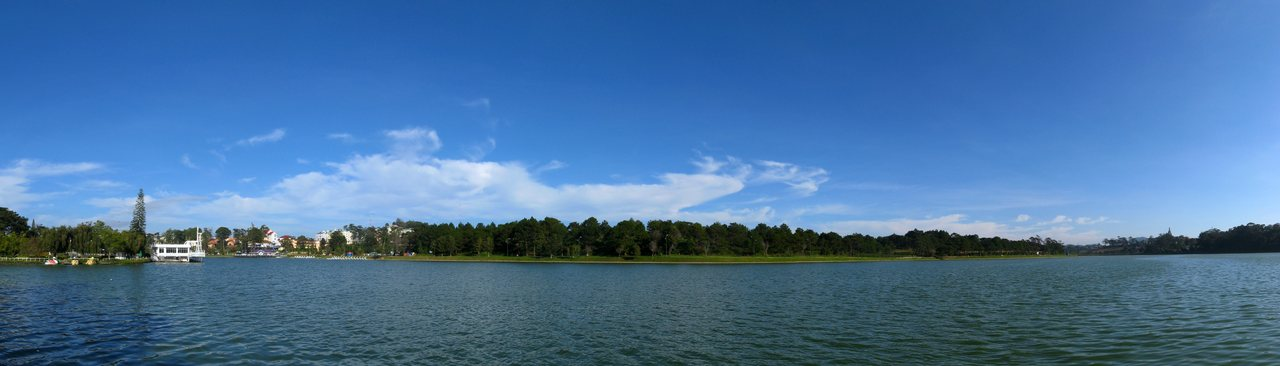

Subject →,Quan hệ,→ Object
n000: sky,over,n001: sea
n000: sky,over,n002: tree
n003: boat,on,n001: sea
n000: sky,over,n003: boat


GNN MagicBrush · prompt · seed 42 · epoch 10
Checkpoint SHA-256: ec85e0d8cc62da125f5a959eaaae5d6c52272e542548ff3d71730b3f8cf85d06
Thao tác dự đoán: [
  {
    "kind": "add_node",
    "before": null,
    "after": {
      "id": "newn001",
      "label": "giraffe",
      "attributes": [
        "large relative to hydrant top"
      ]
    }
  }
]


Subject →,Quan hệ,→ Object
n000: sky,over,n001: sea
n000: sky,over,n002: tree
n003: boat,on,n001: sea
n000: sky,over,n003: boat


In [4]:
boat, boat_source = show_source("travel-7bb0c6b3635205-q100-1")
show_prediction(boat, boat_source, seed=42)


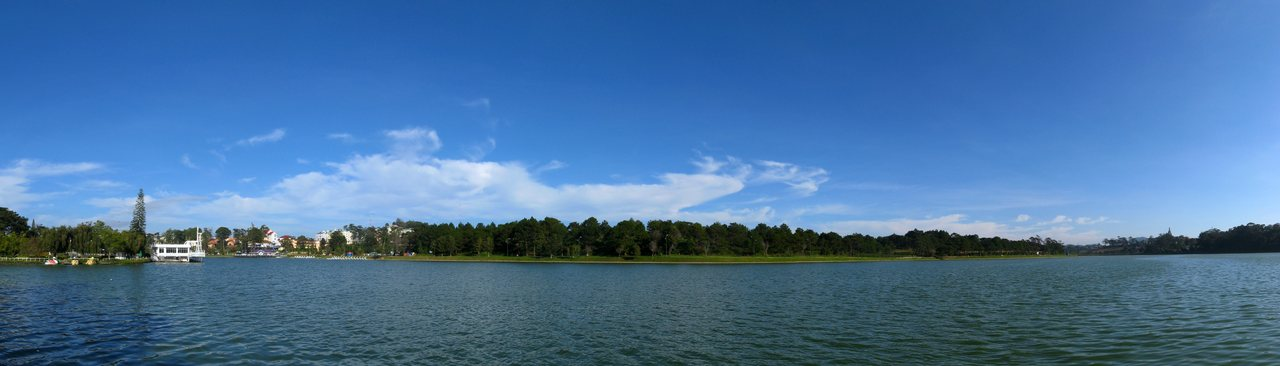
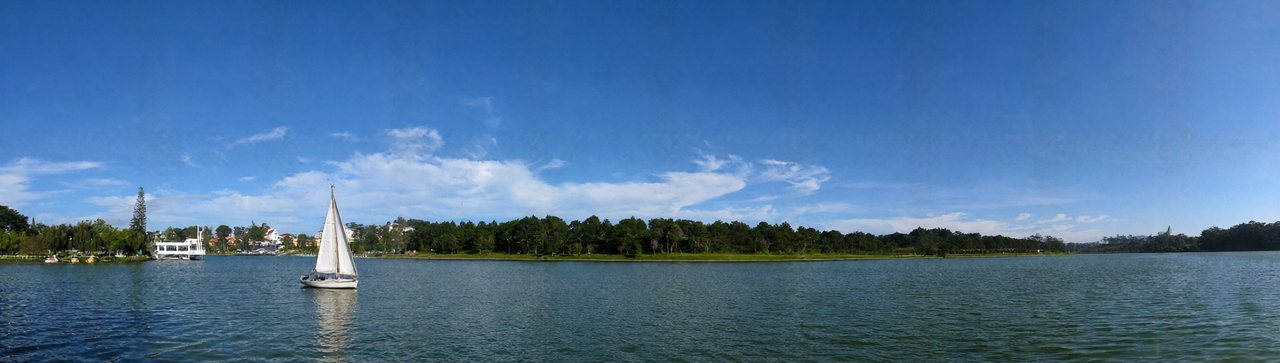

Subject →,Quan hệ,→ Object
n000: sky,over,n002: sea
n001: boat,on,n002: sea
n000: sky,over,n001: boat
n000: sky,over,n003: tree
n000: sky,over,n004: boat
n004: boat,on,n002: sea


E,P,G,Nhãn tay: đúng yêu cầu,Nhãn tay: bảo toàn
1.000,1.000,1.000,True,True


Điều kiện chỉnh sửa: [{'criterion': 'new_instance_in_requested_region', 'value': 1.0, 'reason': None, 'selected': 'n001', 'candidates': ['n001'], 'category_counts': [1, 2]}]
P đủ bằng chứng: True
Lý do hạn chế: —


In [5]:
show_image_evaluation(boat)

GNN thêm nút `giraffe`, sai đối tượng. Trên ảnh Qwen, bộ chấm phát hiện số thuyền tăng từ một lên hai, với chiếc mới trong vùng yêu cầu. Cặp ảnh đạt G = 1.

## 2. Thêm chó trên đá · VN100 · seed 3407

Yêu cầu gồm cả đối tượng và vị trí. Hãy tìm nút `rock` trong đồ thị nguồn, sau đó kiểm tra nút nào được thêm và có cạnh nào nối nó với đá.

travel-a4fe5a686b0396-q200-2
Add a dog standing on the foreground rocks beside the natural pool, leaving the rest of the scene unchanged.


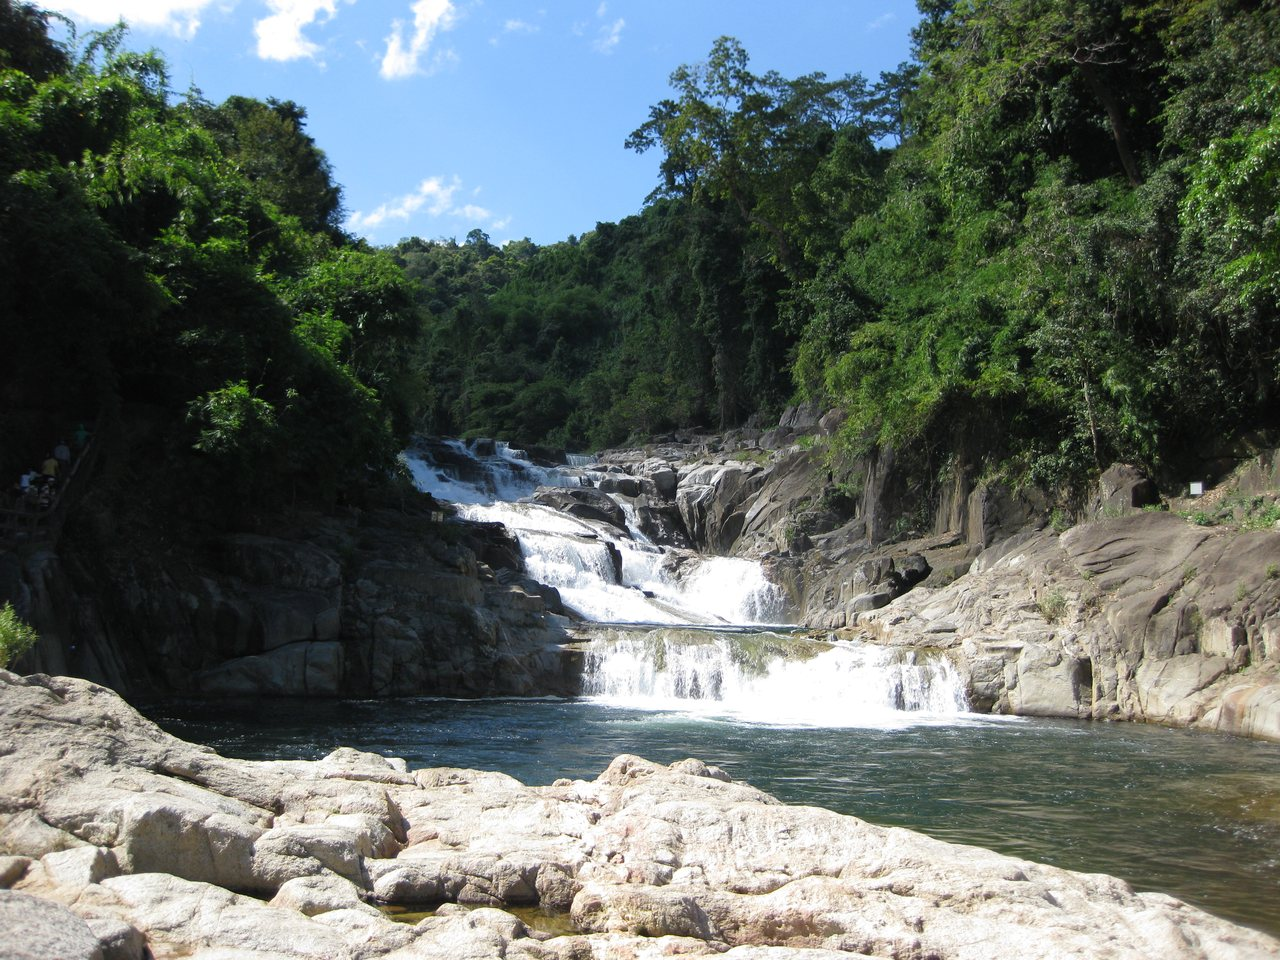

Subject →,Quan hệ,→ Object
n001: sky,over,n002: tree
n001: sky,over,n003: river
n002: tree,beside,n003: river
n000: rock,attached to,n003: river
n001: sky,over,n000: rock
n002: tree,beside,n000: rock


In [6]:
dog, dog_source = show_source("travel-a4fe5a686b0396-q200-2")

In [7]:
show_prediction(dog, dog_source, seed=3407)

GNN MagicBrush · prompt · seed 3407 · epoch 28
Checkpoint SHA-256: cb99d52e2b4ecbb93a04085b2d5a163f529986c477cd8ff6768d2eac6c764702
Thao tác dự đoán: [
  {
    "kind": "add_node",
    "before": null,
    "after": {
      "id": "newn001",
      "label": "dog",
      "attributes": []
    }
  }
]


Subject →,Quan hệ,→ Object
n001: sky,over,n002: tree
n001: sky,over,n003: river
n002: tree,beside,n003: river
n000: rock,attached to,n003: river
n001: sky,over,n000: rock
n002: tree,beside,n000: rock


GNN thêm đúng một nút `dog` và giữ nguyên các nút, cạnh cũ. Nút mới đứng riêng nên đồ thị chỉ thể hiện được một phần yêu cầu. Chi tiết chó đứng trên đá ở tiền cảnh cạnh hồ chưa được mô hình mã hóa.


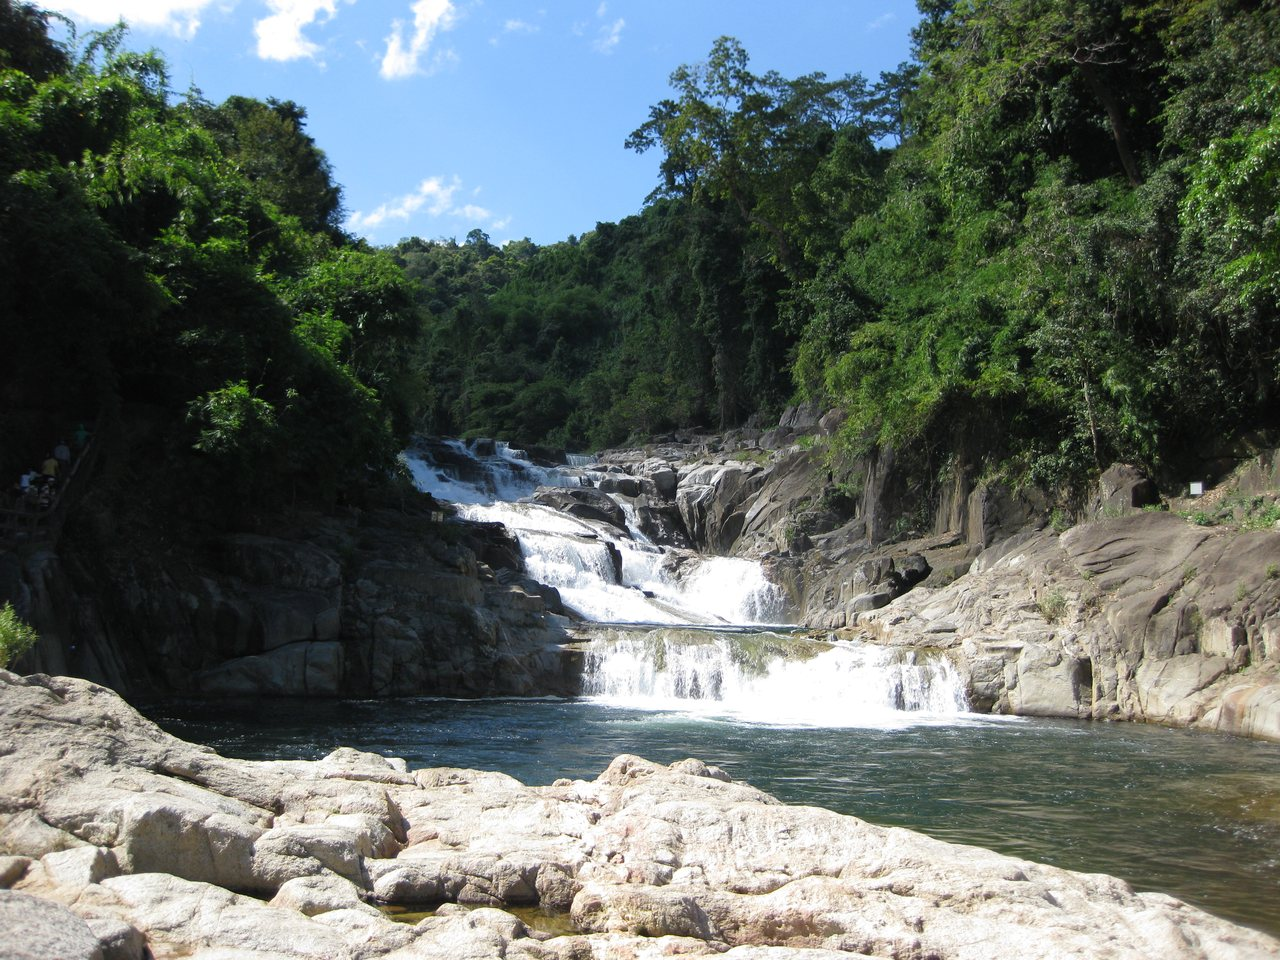
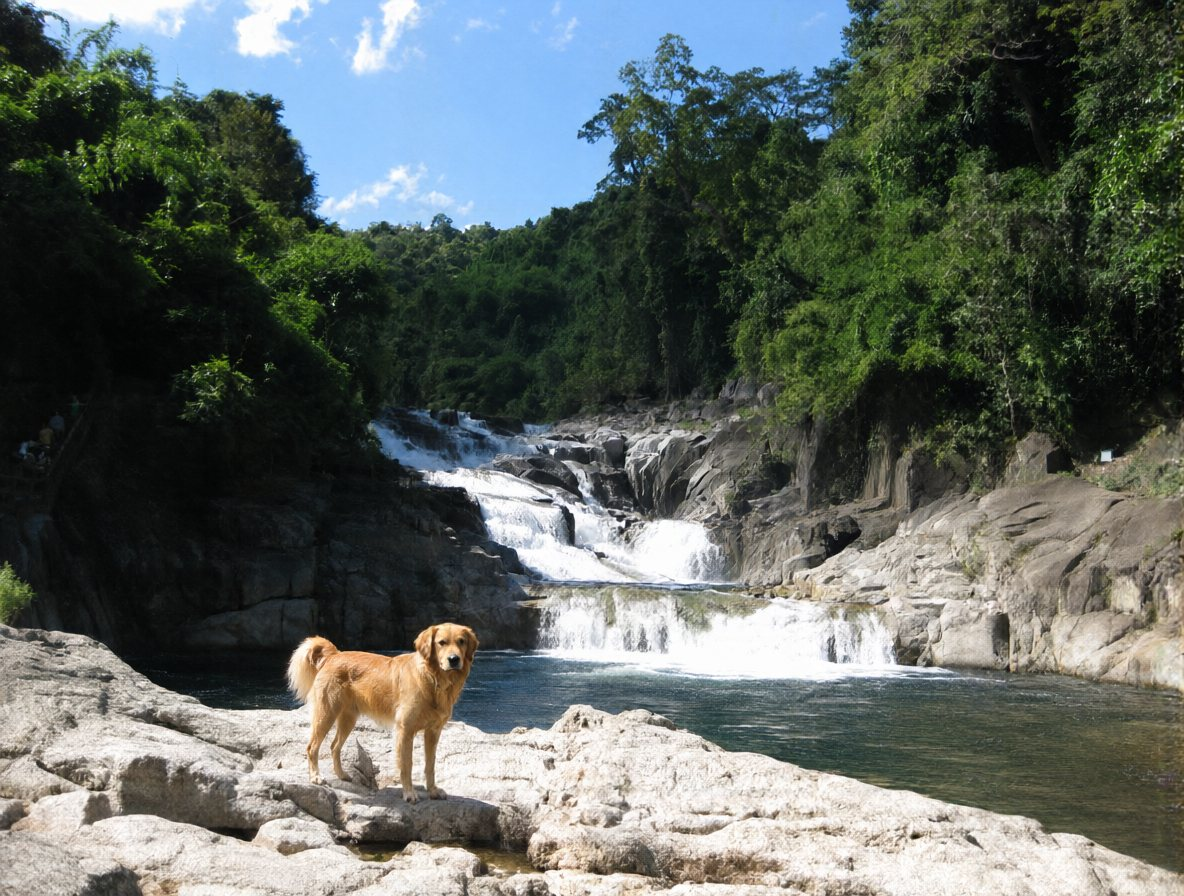

Subject →,Quan hệ,→ Object
n001: sky,over,n003: tree
n002: dog,standing on,n000: rock
n001: sky,over,n002: dog
n001: sky,over,n004: river
n001: sky,over,n000: rock
n002: dog,looking at,n004: river
n002: dog,looking at,n005: water
n000: rock,attached to,n004: river
n003: tree,beside,n004: river
n001: sky,over,n005: water


E,P,G,Nhãn tay: đúng yêu cầu,Nhãn tay: bảo toàn
1.000,0.829,0.829,True,True


Điều kiện chỉnh sửa: [{'criterion': 'new_instance_in_requested_region', 'value': 1.0, 'reason': None, 'selected': 'n002', 'candidates': ['n002'], 'category_counts': [0, 1]}]
P đủ bằng chứng: True
Lý do hạn chế: —


In [8]:
show_image_evaluation(dog)

Trong ảnh Qwen, bộ chấm xác nhận có thêm chó trong vùng yêu cầu (E = 1). Phần đồ thị còn lại có P ≈ 0,829 nên G ≈ 0,829. Người duyệt đánh dấu đạt cả chỉnh sửa lẫn bảo toàn.

## 3. Xóa ghế · MagicBrush test · seed 123

Ca `magicbrush:190052:2` được chọn để minh họa một dự đoán khớp hoàn toàn. Với checkpoint GNN nhánh prompt, seed 123, có **1/59** ca test đạt tiêu chí này. Hãy nhìn vào ảnh và cạnh nối ghế với quầy trước khi chạy ô dự đoán.

magicbrush:190052:2
remove the chairs


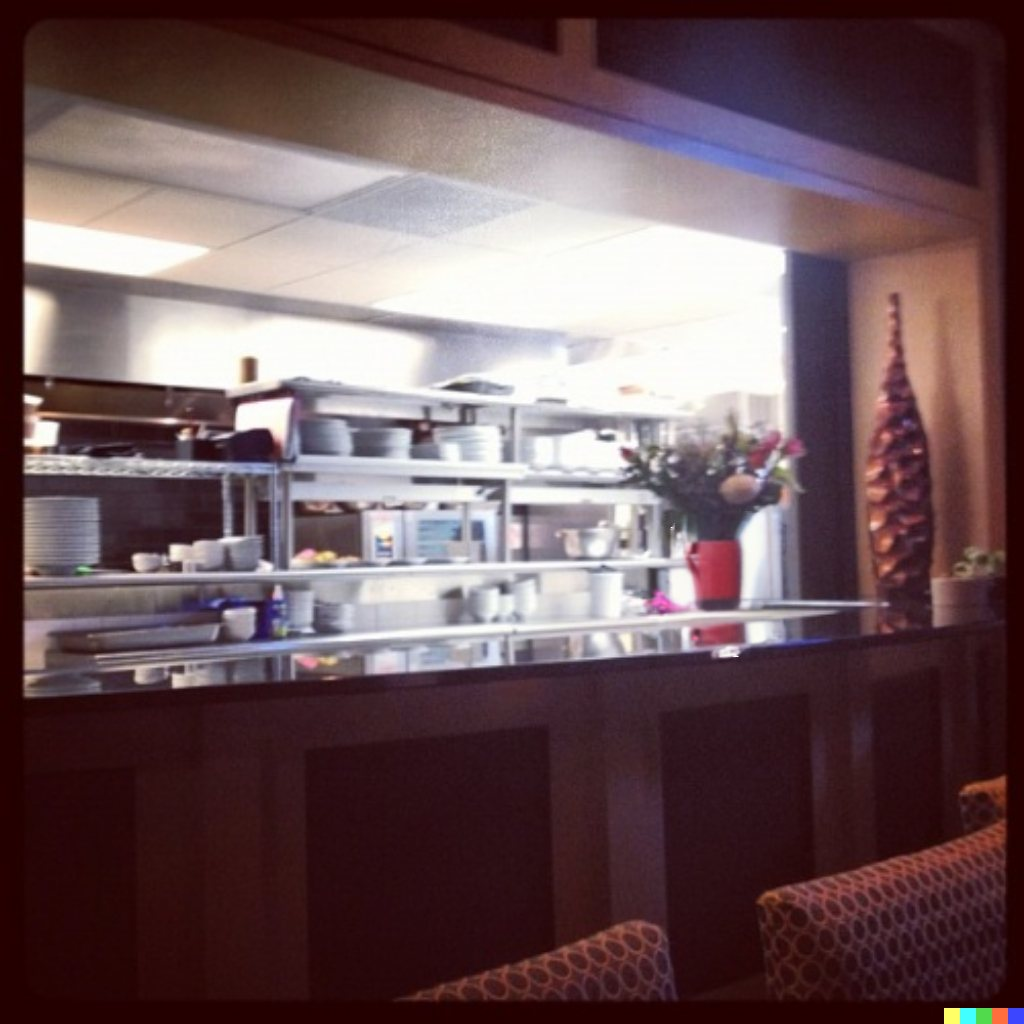

Subject →,Quan hệ,→ Object
n001: chairs,in front of,n002: counter
n003: shelves,behind,n002: counter
n004: dishes,on,n003: shelves
n005: vase,on,n002: counter
n006: flowers,in,n005: vase
n007: decorative vase,behind,n002: counter
n008: plant,on,n002: counter


In [9]:
from task2_graph_editing.magicbrush.dataset import rows
from task2_graph_editing.magicbrush.examples import example
from common.io import sha256

chair = next(row for row in rows("test") if row["id"] == "magicbrush:190052:2")

def show_magicbrush_image(role):
    checksum = chair["images"][role]
    path = ROOT / "data/processed/level2/magicbrush-v1/images" / f"{checksum}.png"
    if sha256(path) != checksum:
        raise ValueError(f"Ảnh sai checksum: {role}")
    display_preview(path, width=460)

print(chair["id"], chair["instruction"], sep="\n")
show_magicbrush_image("source_image")
chairs_source = EditGraph.from_dict(chair["source_graph"])
display(HTML(graph_html(chairs_source.to_dict(), "Đồ thị nguồn MagicBrush", "chair-source")))

In [10]:
chair_ops, chair_graph, chair_checkpoint = predict(chairs_source, chair["instruction"], seed=123)
print("Checkpoint:", chair_checkpoint["checkpoint"])
print("Thao tác GNN:", json.dumps([op.to_dict() for op in chair_ops], ensure_ascii=False, indent=2))
display(HTML(graph_html(chair_graph.to_dict(), "Đồ thị sau khi áp dụng dự đoán", "chair-pred")))

Checkpoint: runs/level2/magicbrush-prompt-intent-v1/prompt/seed-123/best.pt
Thao tác GNN: [
  {
    "kind": "delete_node",
    "before": {
      "id": "n001",
      "label": "chairs",
      "attributes": [
        "cropped",
        "foreground",
        "patterned"
      ]
    },
    "after": null
  },
  {
    "kind": "delete_edge",
    "before": {
      "id": "e001",
      "subject": "n001",
      "predicate": "in front of",
      "object": "n002"
    },
    "after": null
  }
]


Subject →,Quan hệ,→ Object
n003: shelves,behind,n002: counter
n004: dishes,on,n003: shelves
n005: vase,on,n002: counter
n006: flowers,in,n005: vase
n007: decorative vase,behind,n002: counter
n008: plant,on,n002: counter


Khớp toàn bộ thao tác: True
Khớp đồ thị đích: True
Ảnh đích tham chiếu của MagicBrush


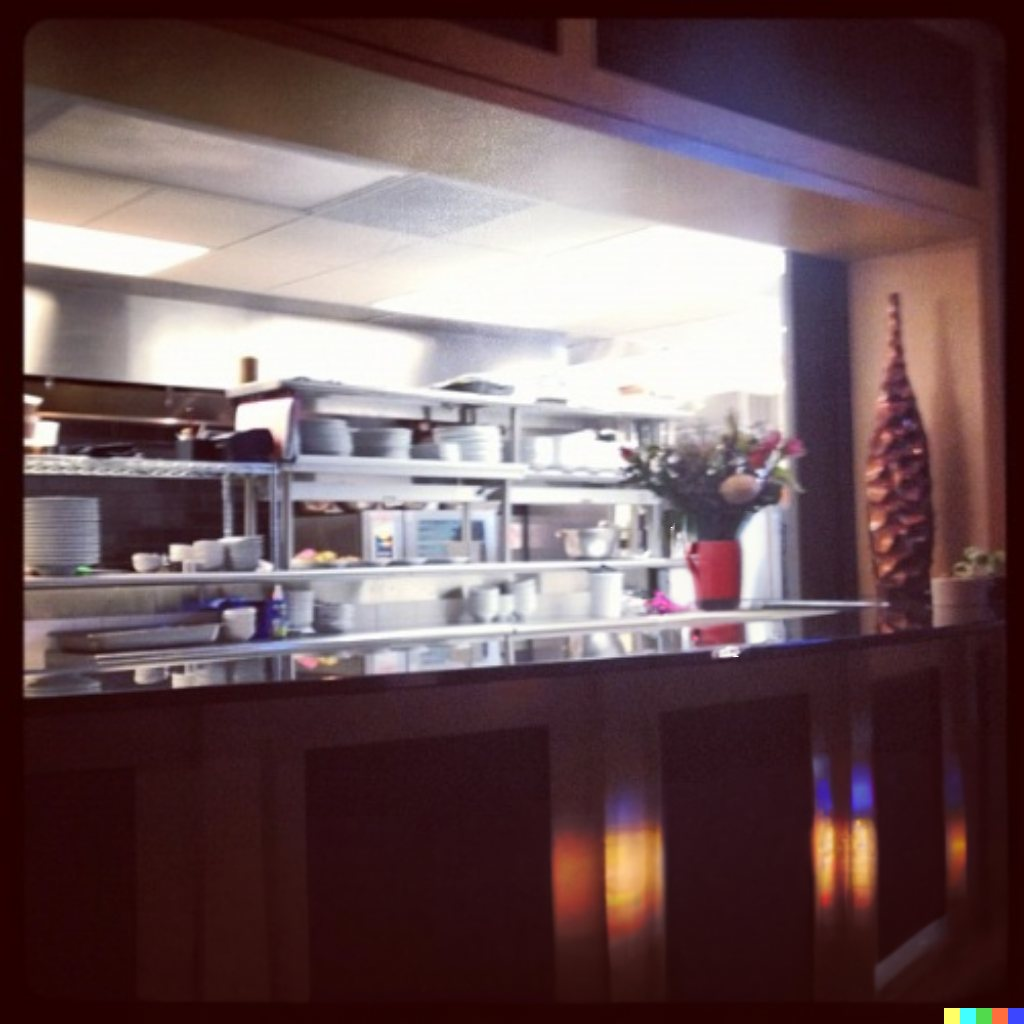

In [11]:
reference = example(chair, chair["operations"])
print("Khớp toàn bộ thao tác:", set(chair_ops) == set(reference.operations))
print("Khớp đồ thị đích:", chair_graph == reference.target)
print("Ảnh đích tham chiếu của MagicBrush")
show_magicbrush_image("target_image")

GNN xóa nút `chairs` và cạnh `chairs → in front of → counter`. Các nút và cạnh khác được giữ lại. Ảnh đích bên trên thuộc cặp dữ liệu MagicBrush.